# NCSN（2019）二维高斯混合实验：从 Score 学习到退火 Langevin 采样

这个 notebook 用一个可以解析求解的二维问题拆解 NCSN 的完整流程。目标不是复刻论文中的 RefineNet 图像网络，而是让每个数学对象都能直接画出来并检查。

完成实验后会得到五组结果：

1. 多尺度高斯噪声如何连接两个相距较远的模态；
2. Denosing Score Matching（DSM）的训练曲线；
3. 神经网络 Score 与解析 Score 的定量误差；
4. 两者在二维平面上的向量场对比；
5. Annealed Langevin Dynamics 从噪声逐步生成双峰样本的过程。

> 运行环境：`conda activate pytorch`。一次“全部运行”即可重现实验，随机种子固定为 42。

## 1. 实验对象与核心公式

真实数据是两个二维单位高斯的混合：

$$
p_{\mathrm{data}}(x)=0.2\,\mathcal N((-5,-5),I)
+0.8\,\mathcal N((5,5),I).
$$

训练时随机选取噪声尺度 $\sigma$，并构造

$$
\tilde x=x_0+\sigma\epsilon,\qquad \epsilon\sim\mathcal N(0,I).
$$

我们让网络预测噪声 $\hat\epsilon_\theta(\tilde x,\sigma)$，再把它换算成 Score：

$$
s_\theta(\tilde x,\sigma)=-\frac{\hat\epsilon_\theta(\tilde x,\sigma)}{\sigma}.
$$

因此下面两种 DSM 写法完全等价：

$$
\|\hat\epsilon_\theta-\epsilon\|^2
=\|\sigma s_\theta+\epsilon\|^2.
$$

预测噪声的参数化在数值上更稳定，也与现代扩散模型常见的 $\epsilon$ 参数化一致。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# 固定随机性，便于复现；输出目录相对于 notebook 所在目录。
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("ncsn_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DIM = 2
DATA_STD = 1.0
MEANS = torch.tensor([[-5.0, -5.0], [5.0, 5.0]], device=DEVICE)
WEIGHTS = torch.tensor([0.2, 0.8], device=DEVICE)

# 几何序列是 NCSN 的典型噪声调度；顺序为从大到小。
SIGMAS = torch.exp(torch.linspace(math.log(10.0), math.log(0.1), 10)).to(DEVICE)

BATCH_SIZE = 512
TRAIN_STEPS = 5_000
LEARNING_RATE = 1e-3
SAMPLE_NUM = 2_000
STEPS_PER_SIGMA = 500
# 这个二维问题的最小尺度方差约为 1；1e-3 让低噪声层也有足够混合时间。
BASE_STEP_SIZE = 1e-3

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print("Noise schedule:", np.round(SIGMAS.cpu().numpy(), 4))
print(f"Figures will be saved to: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Noise schedule: [10.      5.9948  3.5938  2.1544  1.2915  0.7743  0.4642  0.2783  0.1668
  0.1   ]
Figures will be saved to: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/ncsn_outputs


## 2. 数据分布与解析 Score

加噪相当于把原分布与 $\mathcal N(0,\sigma^2I)$ 卷积。因为高斯卷积仍是高斯，所以

$$
p_\sigma(x)=\sum_i\pi_i\mathcal N\!\left(x;\mu_i,(1+\sigma^2)I\right).
$$

其解析 Score 为

$$
\nabla_x\log p_\sigma(x)
=\sum_i r_i(x,\sigma)\frac{\mu_i-x}{1+\sigma^2},
$$

其中 $r_i$ 是样本属于第 $i$ 个分量的后验责任概率。解析 Score 只用于验收网络和采样器，不参与训练。

In [2]:
def sample_data(batch_size):
    # 从 p_data 采样。
    component = torch.multinomial(WEIGHTS, batch_size, replacement=True)
    return MEANS[component] + DATA_STD * torch.randn(batch_size, DIM, device=DEVICE)


def true_score(x, sigma):
    # 计算 p_sigma 的解析 Score；sigma 可为标量张量。
    variance = DATA_STD**2 + sigma**2
    diff = x[:, None, :] - MEANS[None, :, :]
    log_prob = torch.log(WEIGHTS)[None, :] - diff.square().sum(-1) / (2 * variance)
    responsibility = torch.softmax(log_prob, dim=1)
    component_score = -diff / variance
    return (responsibility[:, :, None] * component_score).sum(dim=1)


with torch.no_grad():
    sanity = sample_data(20_000)
    nearest = torch.cdist(sanity, MEANS).argmin(dim=1)
    observed_weights = torch.bincount(nearest, minlength=2).float() / len(sanity)

print("Empirical component weights:", observed_weights.cpu().numpy().round(3))
print("Empirical mean:", sanity.mean(0).cpu().numpy().round(3))

Empirical component weights: [0.196 0.804]
Empirical mean: [3.043 3.049]


## 3. 先观察高斯平滑

代码不需要计算卷积积分。对原始样本直接加 $\sigma\epsilon$，所得样本就服从 $p_\sigma$。小噪声保留清晰双峰；大噪声让低密度区域获得概率质量，使 Langevin 链更容易在模态之间移动。

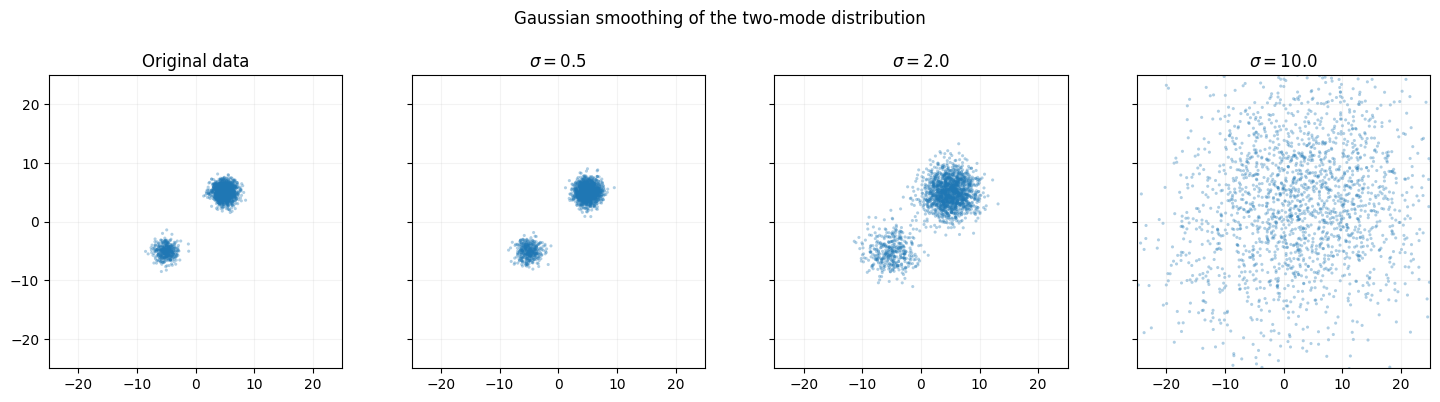

In [3]:
with torch.no_grad():
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), sharex=True, sharey=True)
    for ax, sigma in zip(axes, [0.0, 0.5, 2.0, 10.0]):
        x0 = sample_data(2_000)
        points = x0 if sigma == 0 else x0 + sigma * torch.randn_like(x0)
        points = points.cpu().numpy()
        ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.35, edgecolors="none")
        ax.set_title("Original data" if sigma == 0 else rf"$\sigma={sigma}$")
        ax.set_xlim(-25, 25)
        ax.set_ylim(-25, 25)
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle("Gaussian smoothing of the two-mode distribution", y=1.03)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "01_gaussian_smoothing.png", dpi=160, bbox_inches="tight")
    plt.show()

## 4. Noise Conditional Score Network

网络输入二维坐标和 $\log\sigma$。坐标按最大噪声尺度归一化，避免输入范围过大。一个网络同时服务所有噪声尺度，这就是“Noise Conditional”的含义。

虽然类名是 `ScoreNet`，前向传播返回的是预测噪声；`score()` 方法负责转换为 Score。这样训练目标直观、数值范围也更均衡。

In [4]:
class ScoreNet(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, DIM),
        )

    def forward(self, x, sigma):
        # sigma 的形状为 [B, 1]
        x_scaled = x / SIGMAS[0]
        log_sigma_scaled = torch.log(sigma) / math.log(10.0)
        return self.net(torch.cat([x_scaled, log_sigma_scaled], dim=-1))

    def score(self, x, sigma):
        return -self.forward(x, sigma) / sigma


model = ScoreNet().to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {parameter_count:,}")

ScoreNet(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 33,794


## 5. DSM 训练

每个 batch 独立抽取数据、噪声尺度和标准高斯噪声。模型看不到干净样本 $x_0$，但平方误差回归的最优解满足

$$
\mathbb E\!\left[-\epsilon/\sigma\mid\tilde x=x\right]
=\nabla_x\log p_\sigma(x).
$$

这解释了为什么只用容易获得的条件扰动目标，就能学习未知边缘密度的 Score。

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
losses = []
started = time.perf_counter()
model.train()

for step in range(1, TRAIN_STEPS + 1):
    x0 = sample_data(BATCH_SIZE)
    sigma_index = torch.randint(len(SIGMAS), (BATCH_SIZE,), device=DEVICE)
    sigma = SIGMAS[sigma_index, None]
    epsilon = torch.randn_like(x0)
    x_noisy = x0 + sigma * epsilon

    epsilon_pred = model(x_noisy, sigma)
    loss = (epsilon_pred - epsilon).square().sum(dim=1).mean()

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step == 1 or step % 500 == 0:
        recent = np.mean(losses[-100:])
        print(f"step {step:4d}/{TRAIN_STEPS} | loss(100-step avg)={recent:.5f}")

elapsed = time.perf_counter() - started
print(f"Training finished in {elapsed:.1f} s")

step    1/5000 | loss(100-step avg)=1.98514


step  500/5000 | loss(100-step avg)=1.14286


step 1000/5000 | loss(100-step avg)=1.09512


step 1500/5000 | loss(100-step avg)=1.08569


step 2000/5000 | loss(100-step avg)=1.09467


...

step 3000/5000 | loss(100-step avg)=1.07957


step 3500/5000 | loss(100-step avg)=1.08349


step 4000/5000 | loss(100-step avg)=1.09859


step 4500/5000 | loss(100-step avg)=1.07961


step 5000/5000 | loss(100-step avg)=1.09420
Training finished in 13.2 s


## 6. 定量评估：网络究竟学到了什么

DSM 的训练标签 $-\epsilon/\sigma$ 含有条件噪声，而目标边缘 Score 是其条件期望，因此训练 loss 不会降到零。更直接的检查是在独立样本上将网络与解析 Score 比较。

这里报告两个量：

- `score MSE`：原始 Score 的均方误差；小 $\sigma$ 时 Score 数值更大，因此更严格；
- `scaled MSE`：$\sigma s$ 的均方误差，与加权 DSM 的尺度一致，便于跨噪声级比较。

    sigma      score MSE     scaled MSE
  10.0000       0.000038       0.003774
   5.9948       0.000098       0.003516
   3.5938       0.000183       0.002368
   2.1544       0.000988       0.004586
   1.2915       0.001336       0.002229
   0.7743       0.003887       0.002330
   0.4642       0.009700       0.002090
   0.2783       0.024175       0.001872
   0.1668       0.060798       0.001692
   0.1000       0.180935       0.001809


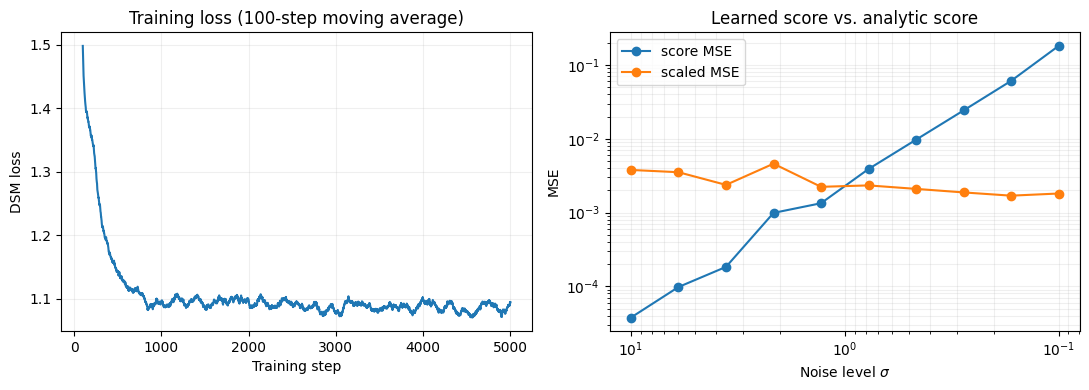

In [6]:
@torch.no_grad()
def evaluate_score(model, n=8_192):
    model.eval()
    rows = []
    for sigma in SIGMAS:
        x0 = sample_data(n)
        x = x0 + sigma * torch.randn_like(x0)
        sigma_batch = sigma.expand(n, 1)
        pred = model.score(x, sigma_batch)
        target = true_score(x, sigma)
        mse = (pred - target).square().mean().item()
        scaled_mse = (sigma * (pred - target)).square().mean().item()
        rows.append((sigma.item(), mse, scaled_mse))
    return np.asarray(rows)


score_metrics = evaluate_score(model)
print(f"{'sigma':>9} {'score MSE':>14} {'scaled MSE':>14}")
for sigma, mse, scaled_mse in score_metrics:
    print(f"{sigma:9.4f} {mse:14.6f} {scaled_mse:14.6f}")

# 用滑动平均呈现趋势，原始 loss 仍保存在 losses 中。
window = 100
loss_smooth = np.convolve(losses, np.ones(window) / window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(window, len(losses) + 1), loss_smooth, lw=1.5)
axes[0].set(xlabel="Training step", ylabel="DSM loss", title=f"Training loss ({window}-step moving average)")
axes[0].grid(alpha=0.2)
axes[1].loglog(score_metrics[:, 0], score_metrics[:, 1], "o-", label="score MSE")
axes[1].loglog(score_metrics[:, 0], score_metrics[:, 2], "o-", label="scaled MSE")
axes[1].invert_xaxis()
axes[1].set(xlabel=r"Noise level $\sigma$", ylabel="MSE", title="Learned score vs. analytic score")
axes[1].legend()
axes[1].grid(alpha=0.2, which="both")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_training_and_score_error.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. 可视化 Score 向量场

Score 指向局部概率密度上升最快的方向。下面在同一网格上比较解析场和网络场。背景颜色表示向量长度，箭头表示方向。选择中等噪声 $\sigma\approx0.77$，既能看到两个模态，也能观察它们之间的连接区域。

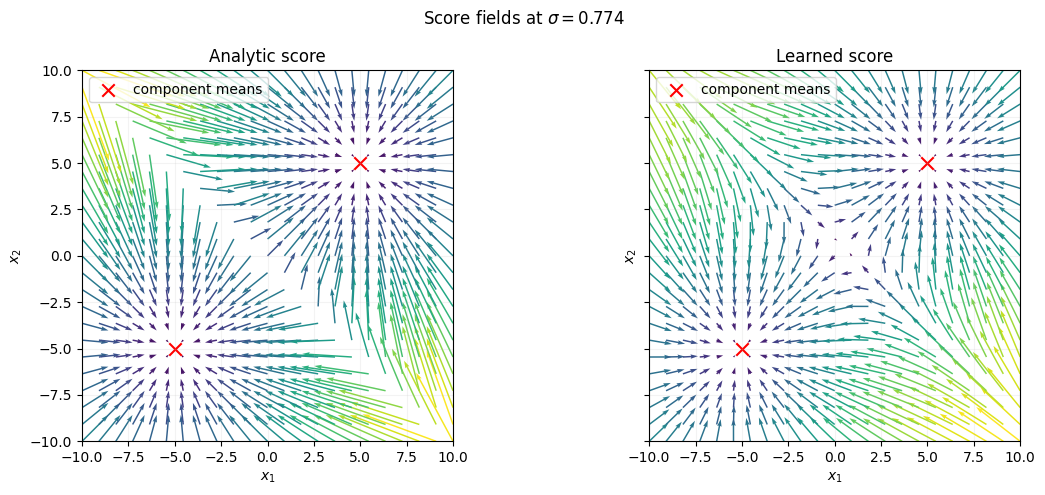

In [7]:
@torch.no_grad()
def plot_score_fields(model, sigma_value=float(SIGMAS[5])):
    grid_1d = torch.linspace(-10, 10, 23, device=DEVICE)
    yy, xx = torch.meshgrid(grid_1d, grid_1d, indexing="ij")
    grid = torch.stack([xx.ravel(), yy.ravel()], dim=1)
    sigma = torch.full((len(grid), 1), sigma_value, device=DEVICE)
    fields = [true_score(grid, torch.tensor(sigma_value, device=DEVICE)), model.score(grid, sigma)]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    titles = ["Analytic score", "Learned score"]
    for ax, field, title in zip(axes, fields, titles):
        g = grid.cpu().numpy()
        f = field.cpu().numpy()
        magnitude = np.linalg.norm(f, axis=1)
        ax.quiver(g[:, 0], g[:, 1], f[:, 0], f[:, 1], magnitude,
                  cmap="viridis", angles="xy", scale_units="xy", scale=2.2, width=0.004)
        ax.scatter(MEANS[:, 0].cpu(), MEANS[:, 1].cpu(), marker="x", c="red", s=80, label="component means")
        ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-10, 10), ylim=(-10, 10))
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
        ax.legend(loc="upper left")
    fig.suptitle(rf"Score fields at $\sigma={sigma_value:.3f}$")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "03_score_fields.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_score_fields(model)

## 8. Annealed Langevin Dynamics

在每个噪声尺度下执行

$$
x_{k+1}=x_k+\frac{\eta_i}{2}s_\theta(x_k,\sigma_i)
+\sqrt{\eta_i}\,z_k,
$$

并令 $\eta_i\propto\sigma_i^2$。高噪声阶段步长大，负责全局移动；低噪声阶段步长小，负责细化样本。切换尺度时不需要手动减去噪声，而是改用下一个条件 Score，使链逐渐追踪更清晰的 $p_{\sigma_i}$。

In [8]:
@torch.no_grad()
def annealed_langevin(model, num_samples=SAMPLE_NUM):
    model.eval()
    x = SIGMAS[0] * torch.randn(num_samples, DIM, device=DEVICE)
    history = [x.cpu().numpy().copy()]

    for level, sigma in enumerate(SIGMAS, start=1):
        step_size = BASE_STEP_SIZE * (sigma / SIGMAS[-1]).square().item()
        sigma_batch = sigma.expand(num_samples, 1)
        for _ in range(STEPS_PER_SIGMA):
            score = model.score(x, sigma_batch)
            x = x + 0.5 * step_size * score + math.sqrt(step_size) * torch.randn_like(x)
        history.append(x.cpu().numpy().copy())
        print(f"level {level:2d}/{len(SIGMAS)} | sigma={sigma.item():.4f} | step={step_size:.6f}")
    return x.cpu().numpy(), history


sampling_started = time.perf_counter()
generated, history = annealed_langevin(model)
print(f"Sampling finished in {time.perf_counter() - sampling_started:.1f} s")

level  1/10 | sigma=10.0000 | step=10.000002
level  2/10 | sigma=5.9948 | step=3.593814


level  3/10 | sigma=3.5938 | step=1.291550


level  4/10 | sigma=2.1544 | step=0.464159


level  5/10 | sigma=1.2915 | step=0.166810


level  6/10 | sigma=0.7743 | step=0.059948
level  7/10 | sigma=0.4642 | step=0.021544


level  8/10 | sigma=0.2783 | step=0.007743
level  9/10 | sigma=0.1668 | step=0.002783


level 10/10 | sigma=0.1000 | step=0.001000
Sampling finished in 2.0 s


## 9. 采样轨迹与最终结果

除了散点图，还检查生成样本被分配到两个最近中心的比例、均值和协方差。理论目标比例为 $[0.2,0.8]$，理论均值为 $(3,3)$。Toy 实验的有限网络和有限 Langevin 步数会带来偏差，但应能恢复两个模态及其明显不对称的权重。

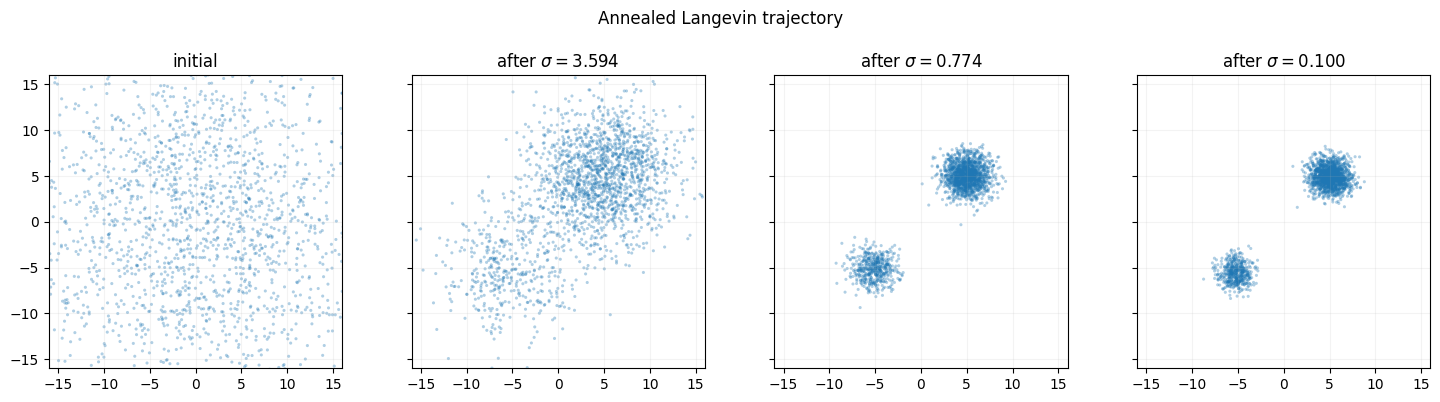

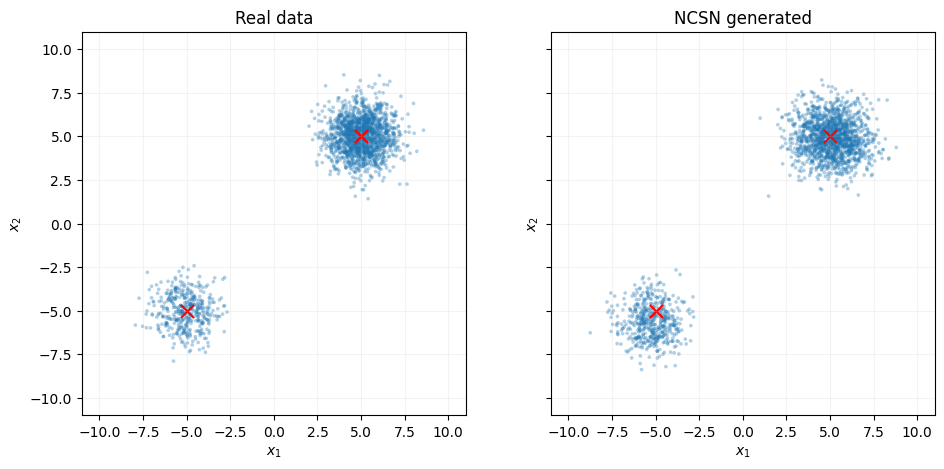

Target weights:    [0.2 0.8]
Real weights:      [0.211 0.79 ]
Generated weights: [0.251 0.749]
Target mean:       [3. 3.]
Real mean:         [2.906 2.898]
Generated mean:    [2.511 2.267]
Generated covariance:
 [[21.283 20.414]
 [20.414 21.92 ]]


In [9]:
stage_ids = [0, 3, 6, 10]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), sharex=True, sharey=True)
for ax, stage in zip(axes, stage_ids):
    points = history[stage]
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.35, edgecolors="none")
    label = "initial" if stage == 0 else rf"after $\sigma={SIGMAS[stage-1].item():.3f}$"
    ax.set_title(label)
    ax.set_xlim(-16, 16)
    ax.set_ylim(-16, 16)
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.suptitle("Annealed Langevin trajectory", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_annealed_langevin_trajectory.png", dpi=160, bbox_inches="tight")
plt.show()

with torch.no_grad():
    real = sample_data(SAMPLE_NUM).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.7), sharex=True, sharey=True)
for ax, points, title in zip(axes, [real, generated], ["Real data", "NCSN generated"]):
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.35, edgecolors="none")
    ax.scatter(MEANS[:, 0].cpu(), MEANS[:, 1].cpu(), marker="x", c="red", s=90)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-11, 11), ylim=(-11, 11))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_generated_vs_real.png", dpi=160, bbox_inches="tight")
plt.show()


def distribution_summary(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    assignment = torch.cdist(points_t, MEANS).argmin(dim=1)
    weights = torch.bincount(assignment, minlength=2).float() / len(points_t)
    return weights.cpu().numpy(), points.mean(0), np.cov(points.T)


real_weights, real_mean, real_cov = distribution_summary(real)
gen_weights, gen_mean, gen_cov = distribution_summary(generated)
print("Target weights:   ", WEIGHTS.cpu().numpy())
print("Real weights:     ", np.round(real_weights, 3))
print("Generated weights:", np.round(gen_weights, 3))
print("Target mean:      ", np.array([3.0, 3.0]))
print("Real mean:        ", np.round(real_mean, 3))
print("Generated mean:   ", np.round(gen_mean, 3))
print("Generated covariance:\n", np.round(gen_cov, 3))

## 10. 如何解读结果

- `01_gaussian_smoothing.png`：展示为什么多尺度噪声能缓解低密度区域与模态隔离问题。
- `02_training_and_score_error.png`：训练 loss 下降说明网络在拟合 DSM 目标；独立的解析 Score 误差才是更直接的正确性检查。
- `03_score_fields.png`：方向一致说明网络学会了概率密度的梯度，而不仅是记住两个中心。
- `04_annealed_langevin_trajectory.png`：样本从宽噪声逐渐收缩到两个模态。
- `05_generated_vs_real.png`：用于检查最终形状、位置和混合权重。

### 常见现象

1. **训练 loss 不为零**：同一个加噪点可能来自不同的 $x_0$ 和 $\epsilon$，网络学习的是条件期望。
2. **小噪声的原始 Score MSE 较大**：除以很小的 $\sigma$ 会放大误差，因此还应看 scaled MSE 和向量场。
3. **生成权重不是精确的 0.2:0.8**：有限训练、离散步长和有限采样步数都会引入偏差。重复运行时固定随机种子可区分算法偏差与随机波动。

### 实验流程总览

$$
x_0\sim p_{\mathrm{data}}
\longrightarrow \tilde x=x_0+\sigma\epsilon
\longrightarrow \text{DSM 训练}
\longrightarrow s_\theta\approx\nabla\log p_\sigma
\longrightarrow \text{Annealed Langevin}
\longrightarrow x_{\mathrm{generated}}.
$$